# 20 · Clusters, transfer and the need for independent labels

**Time:** 45 minutes · **Audience:** undergraduate / introductory graduate GIS and Earth science.

**By the end:** cluster embeddings; test stability without confusing label IDs; design a defensible validation study.

[Run in JupyterLite](https://jltobias.github.io/JupyterLite-zarr-sql-views/lite/lab/index.html?path=20_tessera_clusters.ipynb) · [Earth lab](https://jltobias.github.io/JupyterLite-zarr-sql-views/lab/) · [Sources and licenses](https://jltobias.github.io/JupyterLite-zarr-sql-views/book/credits.html)

Run cells from top to bottom with **Shift+Enter**. The first kernel start downloads Python WebAssembly packages.
The bundled exercises need no data-service account. Save a copy with **File → Save and Export Notebook As** before clearing browser storage.

![Four-stage workflow: STAC discovery, Zarr reading, SQL selection, linked views](assets/pipeline.svg)

In [1]:
from course import *
import numpy as np
import matplotlib.pyplot as plt
print('Ready: Python + NumPy + local teaching data')

Ready: Python + NumPy + local teaching data


## 1. Group vectors without pretending to know their classes

Spherical k-means groups normalized vectors by direction. Choose `k=4` as an experiment, not a claim that there are four
land-cover types. We fit on valid 2025 Lagos pixels. Cluster IDs are arbitrary; neither the algorithm nor this lesson supplies
verified labels such as “wetland,” “informal settlement,” or “flood-vulnerable.”

**Predict:** could two runs find the same groups but assign them different ID numbers?

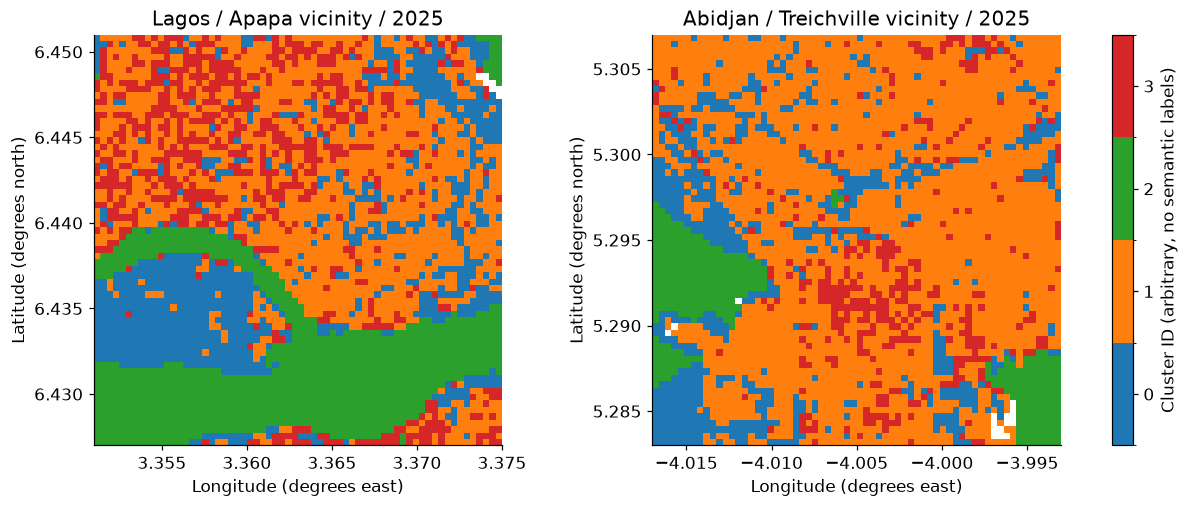

In [2]:
from tessera import load_tessera, unit_vectors, spherical_kmeans, assign_clusters, adjusted_rand, scalar_map
d=load_tessera('lagos'); other=load_tessera('abidjan')
U=unit_vectors(d['embedding'][-1]); V=unit_vectors(other['embedding'][-1])
centers=spherical_kmeans(U,k=4,seed=7)
labels,distance=assign_clusters(U,centers)
other_labels,other_distance=assign_clusters(V,centers)
from matplotlib.colors import ListedColormap, BoundaryNorm
cluster_colors=ListedColormap(plt.get_cmap('tab10').colors[:4])
cluster_norm=BoundaryNorm(np.arange(-.5,4.5),4)
fig,axes=plt.subplots(1,2,figsize=(11,4.5),layout='constrained')
for ax,item,ids in [(axes[0],d,labels),(axes[1],other,other_labels)]:
    im=scalar_map(ax,item,np.ma.masked_less(ids,0),item['city']['title']+' / 2025',
                  cmap=cluster_colors,norm=cluster_norm)
fig.colorbar(im,ax=axes,ticks=range(4),label='Cluster ID (arbitrary, no semantic labels)')
plt.show()

## 2. Measure stability with a label-invariant comparison

Adjusted Rand index compares pairs of points grouped together. It does not require matching cluster numbers.
One means the partitions agree; a value near zero is the chance-adjusted reference, and negative values are possible.
Agreement is a reproducibility diagnostic, not accuracy against reality.

In [3]:
for seed in [7,19,41]:
    alternative=spherical_kmeans(U,k=4,seed=seed)
    alt_labels,_=assign_clusters(U,alternative)
    print('Seed',seed,'adjusted Rand agreement:',round(adjusted_rand(labels,alt_labels),4))
print('ID-renaming check:',adjusted_rand(labels,np.where(labels>=0,3-labels,-1)))

Seed 7 adjusted Rand agreement: 1.0
Seed 19 adjusted Rand agreement: 0.9845
Seed 41 adjusted Rand agreement: 1.0
ID-renaming check: 1.0


## 3. Transfer asks a different question

Assigning Abidjan vectors to Lagos centers demonstrates transfer of a fixed partition. It does not validate the same
land-cover meanings in both places. Compare distances to the assigned centers; larger distances can motivate investigation
of distribution differences, but they are not calibrated out-of-distribution probabilities.

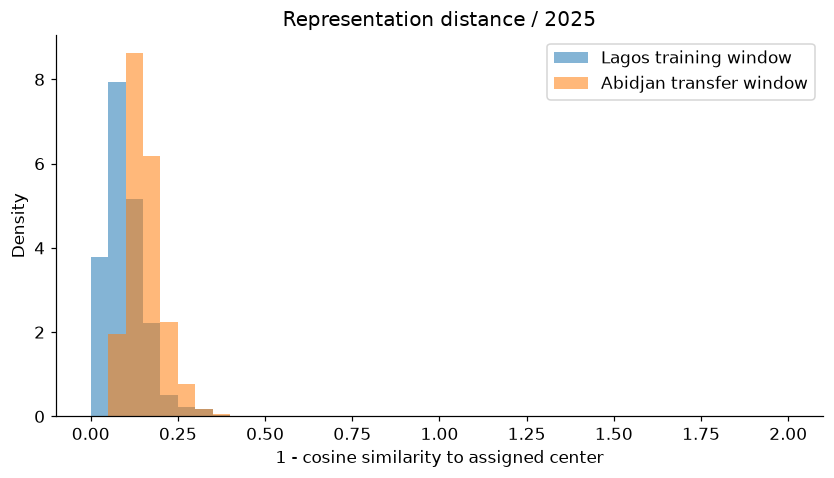

Lagos median distance: 0.0881
Abidjan median distance: 0.1464


In [4]:
fig,ax=plt.subplots()
for title,dist in [('Lagos training window',distance),('Abidjan transfer window',other_distance)]:
    ax.hist(dist[np.isfinite(dist)],bins=np.linspace(0,2,41),density=True,alpha=.55,label=title)
ax.set(xlabel='1 - cosine similarity to assigned center',ylabel='Density',title='Representation distance / 2025')
ax.legend();plt.show()
for title,dist in [('Lagos',distance),('Abidjan',other_distance)]:
    print(title,'median distance:',round(float(np.nanmedian(dist)),4))

## 4. Design the study that these clusters cannot replace

For a coastal vegetation or impervious-surface question, obtain independent, dated reference labels. Use a shared class
definition with local expertise. Separate spatial blocks before training and tuning: neighboring pixels can share conditions
and make random train/test splits overly optimistic. Keep a city or year held out to test transfer explicitly.

This map proposes four geographic blocks. It does not claim a valid buffer distance; select separation using spatial
dependence and the intended use. No accuracy score is reported because this package contains no independent class labels.

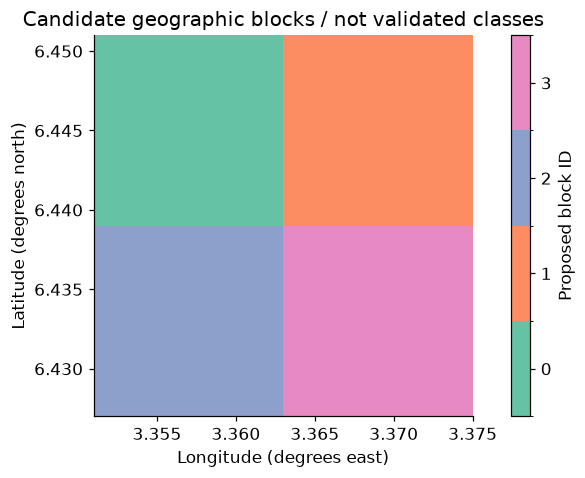

{
  "target": "Independently defined coastal vegetation class",
  "labels_needed": "Dated field or expert interpretation, with uncertainty and permissions",
  "split": "Separated geographic blocks; untouched city/year transfer set",
  "checks": [
    "Class confusion matrix",
    "Per-class recall and precision",
    "Calibration if probabilities are used"
  ],
  "limitations": [
    "Tiny convenience windows",
    "No reference labels bundled",
    "No social vulnerability inferred from imagery"
  ]
}


In [5]:
rows,cols=np.indices((64,64))
blocks=(rows>=32).astype(int)*2+(cols>=32).astype(int)
fig,ax=plt.subplots();im=scalar_map(ax,d,blocks,'Candidate geographic blocks / not validated classes',
                                  cmap=ListedColormap(plt.get_cmap('Set2').colors[:4]),norm=cluster_norm)
fig.colorbar(im,ax=ax,ticks=range(4),label='Proposed block ID');plt.show()
validation_plan={
 'target':'Independently defined coastal vegetation class',
 'labels_needed':'Dated field or expert interpretation, with uncertainty and permissions',
 'split':'Separated geographic blocks; untouched city/year transfer set',
 'checks':['Class confusion matrix','Per-class recall and precision','Calibration if probabilities are used'],
 'limitations':['Tiny convenience windows','No reference labels bundled','No social vulnerability inferred from imagery']}
print(json.dumps(validation_plan,indent=2))

## Try it yourself

Repeat with k=3 and k=6. Which geographic boundaries persist? Write a label-collection plan that could distinguish an interesting cluster from a validated land-cover class.

## Check your reasoning

Cluster stability, geographical coherence, and predictive accuracy answer different questions. Never use the cluster IDs as ground truth for reporting model accuracy.

## Evidence journal

Write four sentences: **what I observed; how I calculated it; what this cannot establish; what evidence I need next**.
For any figure you reuse, retain its units, date or scenario, data origin, transformations, and attribution.

## Sources and credit

- [TESSERA project](https://geotessera.org/) and [model repository](https://github.com/ucam-eo/tessera), University of Cambridge and collaborators.
- [Feng et al., TESSERA: Temporal Embeddings of Surface Spectra for Earth Representation and Analysis](https://doi.org/10.48550/arXiv.2506.20380), 2025, revised 2026.
- [GeoTessera Python client](https://github.com/ucam-eo/geotessera), MIT; pinned preparation commit in the provenance.
- [dClimate global-store documentation](https://github.com/dClimate/tessera-embeddings/blob/main/docs/global-store.md): annual v1.1-dclimate embeddings and observation counts.
- [Bundled source snapshot, coordinates, transformations and checksums](https://jltobias.github.io/JupyterLite-zarr-sql-views/data/tessera-provenance.json). Embedding data: CC0-1.0; [upstream terms and advisory guidelines](https://github.com/ucam-eo/tessera/blob/master/aup.md).

Teaching adaptation of [dzole0311/zarr-sql-views](https://github.com/dzole0311/zarr-sql-views), ISC.
Original teaching code and prose: JupyterLite-zarr-sql-views contributors, ISC. Data keep their separate licenses.

In [6]:
print('LESSON COMPLETE: 20_tessera_clusters')

LESSON COMPLETE: 20_tessera_clusters
